Supply analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'
PURPLE = '#8E44AD'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


In [2]:
from google.colab import files

print("Upload listings.csv.gz")
uploaded = files.upload()

# pandas reads .gz natively — no manual decompression needed
df = pd.read_csv('listings.csv.gz', low_memory=False)

print(f"Rows    : {len(df):,}")
print(f"Columns : {df.shape[1]}")
print()
print("Column names:")
for i, col in enumerate(df.columns):
    print(f"  {i:>3}  {col}")


Upload listings.csv.gz


Saving listings.csv.gz to listings.csv.gz
Rows    : 91,954
Columns : 90

Column names:
    0  id
    1  listing_url
    2  scrape_id
    3  last_scraped
    4  source
    5  name
    6  description
    7  neighborhood_overview
    8  picture_url
    9  host_id
   10  host_url
   11  host_profile_id
   12  host_profile_url
   13  host_name
   14  host_since
   15  hosts_time_as_user_years
   16  hosts_time_as_user_months
   17  hosts_time_as_host_years
   18  hosts_time_as_host_months
   19  host_location
   20  host_about
   21  host_response_time
   22  host_response_rate
   23  host_acceptance_rate
   24  host_is_superhost
   25  host_thumbnail_url
   26  host_picture_url
   27  host_neighbourhood
   28  host_listings_count
   29  host_total_listings_count
   30  host_verifications
   31  host_has_profile_pic
   32  host_identity_verified
   33  neighbourhood
   34  neighbourhood_cleansed
   35  neighbourhood_group_cleansed
   36  latitude
   37  longitude
   38  property_type
   39 

Clean and select columns

In [3]:
# Select the columns we need — Inside Airbnb listings has 70+ columns
keep = [
    'id', 'name',
    'host_id', 'host_name', 'host_since', 'host_is_superhost',
    'host_listings_count', 'host_total_listings_count',
    'neighbourhood_cleansed', 'neighbourhood_group_cleansed',
    'latitude', 'longitude',
    'room_type', 'property_type', 'accommodates',
    'bathrooms_text', 'bedrooms', 'beds',
    'price',
    'minimum_nights', 'maximum_nights',
    'number_of_reviews', 'number_of_reviews_ltm',
    'first_review', 'last_review', 'reviews_per_month',
    'availability_30', 'availability_60',
    'availability_90', 'availability_365',
    'calculated_host_listings_count',
    'review_scores_rating', 'review_scores_cleanliness',
    'review_scores_location', 'review_scores_value',
    'instant_bookable',
]

# Only keep columns that actually exist in this version of the dataset
keep = [c for c in keep if c in df.columns]
df   = df[keep].copy()

# Clean price: "$1,250.00" → 1250.0
df['price'] = (df['price'].astype(str)
               .str.replace('[\$,]', '', regex=True)
               .replace('nan', np.nan)
               .astype(float))

# Clean host_since → datetime
if 'host_since' in df.columns:
    df['host_since'] = pd.to_datetime(df['host_since'], errors='coerce')

# Clean review dates
for col in ['first_review', 'last_review']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

# Remove implausible prices
df = df[(df['price'] > 0) & (df['price'] < 5000)]

# Borough column (may be named differently)
borough_col = 'neighbourhood_group_cleansed' if 'neighbourhood_group_cleansed' in df.columns else 'neighbourhood_cleansed'

print(f"Clean dataset: {len(df):,} listings")
print(f"Price range: £{df['price'].min():.0f} – £{df['price'].max():,.0f}")
print(f"Boroughs/areas: {df[borough_col].nunique()}")
print(f"Neighbourhoods: {df['neighbourhood_cleansed'].nunique()}")
print()
print(df[['id','host_id','neighbourhood_cleansed','room_type','price',
          'availability_365','number_of_reviews']].head(5).to_string(index=False))


Clean dataset: 59,810 listings
Price range: £10 – £4,950
Boroughs/areas: 0
Neighbourhoods: 33

   id  host_id neighbourhood_cleansed       room_type  price  availability_365  number_of_reviews
11551    43039                Lambeth Entire home/apt  267.5               349                197
13913    54730              Islington    Private room  127.0               350                 57
15400    60302 Kensington and Chelsea Entire home/apt  137.5               159                 98
24328    41759             Wandsworth Entire home/apt  228.0               272                 97
36299   155938   Richmond upon Thames Entire home/apt  290.0               350                117


Top-level supply KPIs

In [4]:
n_listings  = len(df)
n_hosts     = df['host_id'].nunique()
n_areas     = df[borough_col].nunique()
avg_price   = df['price'].median()
entire_home = (df['room_type'] == 'Entire home/apt').sum()
entire_pct  = entire_home / n_listings * 100
superhosts  = df[df['host_is_superhost'] == 't']['host_id'].nunique() if 'host_is_superhost' in df.columns else 0

print("=" * 55)
print("SUPPLY-SIDE KPIs — LONDON AIRBNB MARKET")
print("=" * 55)
print(f"  Total active listings      : {n_listings:>8,}")
print(f"  Unique hosts               : {n_hosts:>8,}")
print(f"  Listings per host (avg)    : {n_listings/n_hosts:>8.2f}")
print(f"  Boroughs / areas covered   : {n_areas:>8,}")
print(f"  Median nightly price       : £{avg_price:>7,.0f}")
print(f"  Entire home listings       : {entire_home:>8,}  ({entire_pct:.1f}%)")
if superhosts > 0:
    print(f"  Superhosts                 : {superhosts:>8,}  ({superhosts/n_hosts*100:.1f}% of hosts)")


SUPPLY-SIDE KPIs — LONDON AIRBNB MARKET
  Total active listings      :   59,810
  Unique hosts               :   28,959
  Listings per host (avg)    :     2.07
  Boroughs / areas covered   :        0
  Median nightly price       : £    175
  Entire home listings       :   40,447  (67.6%)
  Superhosts                 :    6,861  (23.7% of hosts)


Host concentration: professional vs casual hosts

In [5]:
# Classify hosts by number of listings
host_listings = df.groupby('host_id')['id'].count().reset_index()
host_listings.columns = ['host_id', 'listing_count']

def classify_host(n):
    if n == 1:   return 'Casual (1 listing)'
    elif n <= 3: return 'Small multi (2–3)'
    elif n <= 9: return 'Medium multi (4–9)'
    else:        return 'Professional (10+)'

host_listings['host_type'] = host_listings['listing_count'].apply(classify_host)

type_summary = host_listings.groupby('host_type').agg(
    hosts=('host_id', 'count'),
    total_listings=('listing_count', 'sum')
).reset_index()
type_summary['host_share_pct']    = type_summary['hosts']           / type_summary['hosts'].sum() * 100
type_summary['listing_share_pct'] = type_summary['total_listings']  / type_summary['total_listings'].sum() * 100

print("Host Concentration:")
print()
print(f"  {'Host Type':<28}  {'Hosts':>8}  {'Host %':>8}  {'Listings':>10}  {'Listing %':>10}")
print("-" * 72)
for _, row in type_summary.sort_values('listing_share_pct', ascending=False).iterrows():
    print(f"  {row['host_type']:<28}  {int(row['hosts']):>8,}  "
          f"{row['host_share_pct']:>7.1f}%  {int(row['total_listings']):>10,}  "
          f"{row['listing_share_pct']:>9.1f}%")
print()
print("Key question: do a small number of professional hosts")
print("dominate supply, crowding out casual home-sharing?")


Host Concentration:

  Host Type                        Hosts    Host %    Listings   Listing %
------------------------------------------------------------------------
  Casual (1 listing)              21,639     74.7%      21,639       36.2%
  Professional (10+)                 747      2.6%      17,432       29.1%
  Small multi (2–3)                4,761     16.4%      10,842       18.1%
  Medium multi (4–9)               1,812      6.3%       9,897       16.5%

Key question: do a small number of professional hosts
dominate supply, crowding out casual home-sharing?


Gini coefficient: how concentrated is supply?

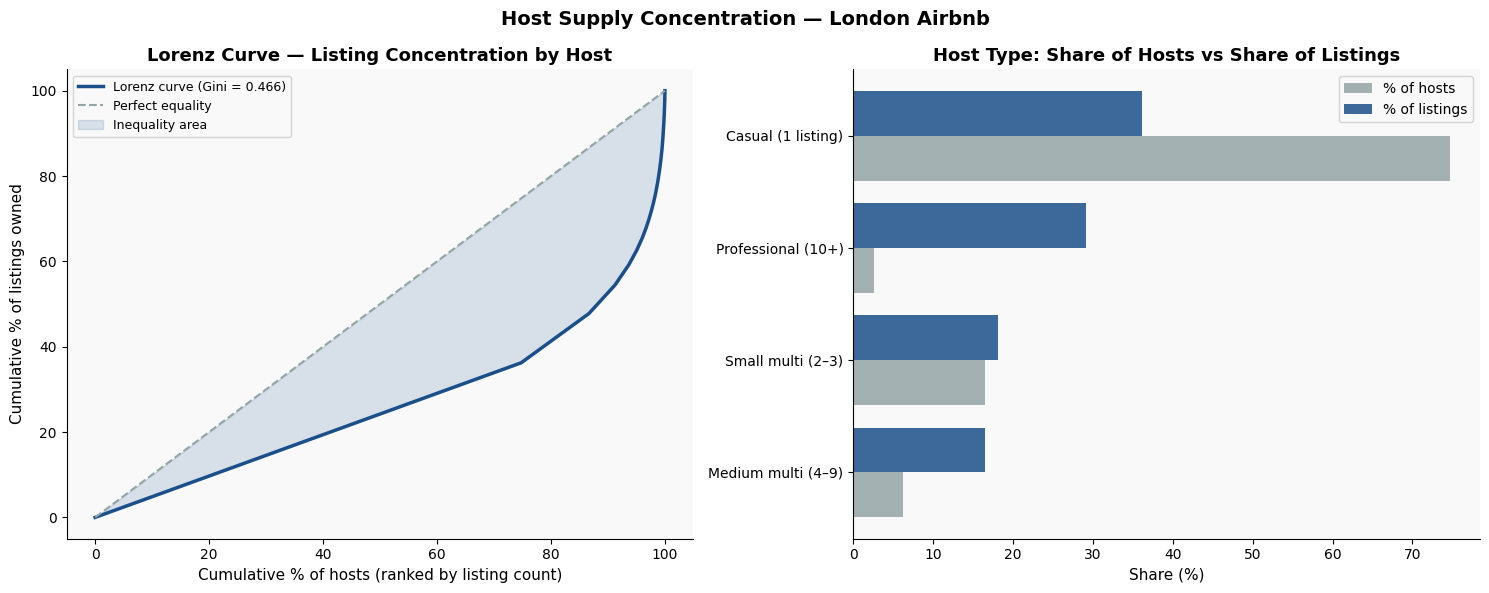

Gini coefficient: 0.466
Reference: 0 = perfectly equal, 1 = one host owns everything
UK income Gini ~ 0.35. A value above 0.6 indicates high market concentration.


In [6]:
def gini_coefficient(values):
    """
    Gini coefficient measures inequality in a distribution.
    0 = perfectly equal (every host has the same number of listings)
    1 = perfectly unequal (one host owns everything)
    Widely used in economics to measure market concentration.
    """
    v = np.sort(np.array(values, dtype=float))
    n = len(v)
    return (2 * np.sum(np.arange(1, n+1) * v) - (n + 1) * np.sum(v)) / (n * np.sum(v))

gini = gini_coefficient(host_listings['listing_count'])

# Lorenz curve
sorted_vals  = np.sort(host_listings['listing_count'].values)
cum_hosts    = np.arange(1, len(sorted_vals) + 1) / len(sorted_vals)
cum_listings = np.cumsum(sorted_vals) / sorted_vals.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Host Supply Concentration — London Airbnb', fontsize=14, fontweight='bold')

# Lorenz curve
axes[0].plot(cum_hosts * 100, cum_listings * 100,
             color=BLUE, lw=2.5, label=f'Lorenz curve (Gini = {gini:.3f})')
axes[0].plot([0, 100], [0, 100], color=GREY, lw=1.5, linestyle='--',
             label='Perfect equality')
axes[0].fill_between(cum_hosts * 100, cum_listings * 100, cum_hosts * 100,
                     alpha=0.15, color=BLUE, label='Inequality area')
axes[0].set_title('Lorenz Curve — Listing Concentration by Host', fontweight='bold')
axes[0].set_xlabel('Cumulative % of hosts (ranked by listing count)')
axes[0].set_ylabel('Cumulative % of listings owned')
axes[0].legend(fontsize=9)

# Host type bar
type_plot = type_summary.sort_values('listing_share_pct', ascending=True)
x = range(len(type_plot))
width = 0.4
axes[1].barh([i - width/2 for i in x], type_plot['host_share_pct'],
             height=width, label='% of hosts', color=GREY, alpha=0.85)
axes[1].barh([i + width/2 for i in x], type_plot['listing_share_pct'],
             height=width, label='% of listings', color=BLUE, alpha=0.85)
axes[1].set_yticks(x)
axes[1].set_yticklabels(type_plot['host_type'])
axes[1].set_title('Host Type: Share of Hosts vs Share of Listings', fontweight='bold')
axes[1].set_xlabel('Share (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '01_host_concentration.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Gini coefficient: {gini:.3f}")
print(f"Reference: 0 = perfectly equal, 1 = one host owns everything")
print(f"UK income Gini ~ 0.35. A value above 0.6 indicates high market concentration.")


Supply by borough and room type

Supply by Borough (Top 15):
Empty DataFrame
Columns: [neighbourhood_group_cleansed, listings, hosts, median_price, avg_availability, entire_home_pct]
Index: []


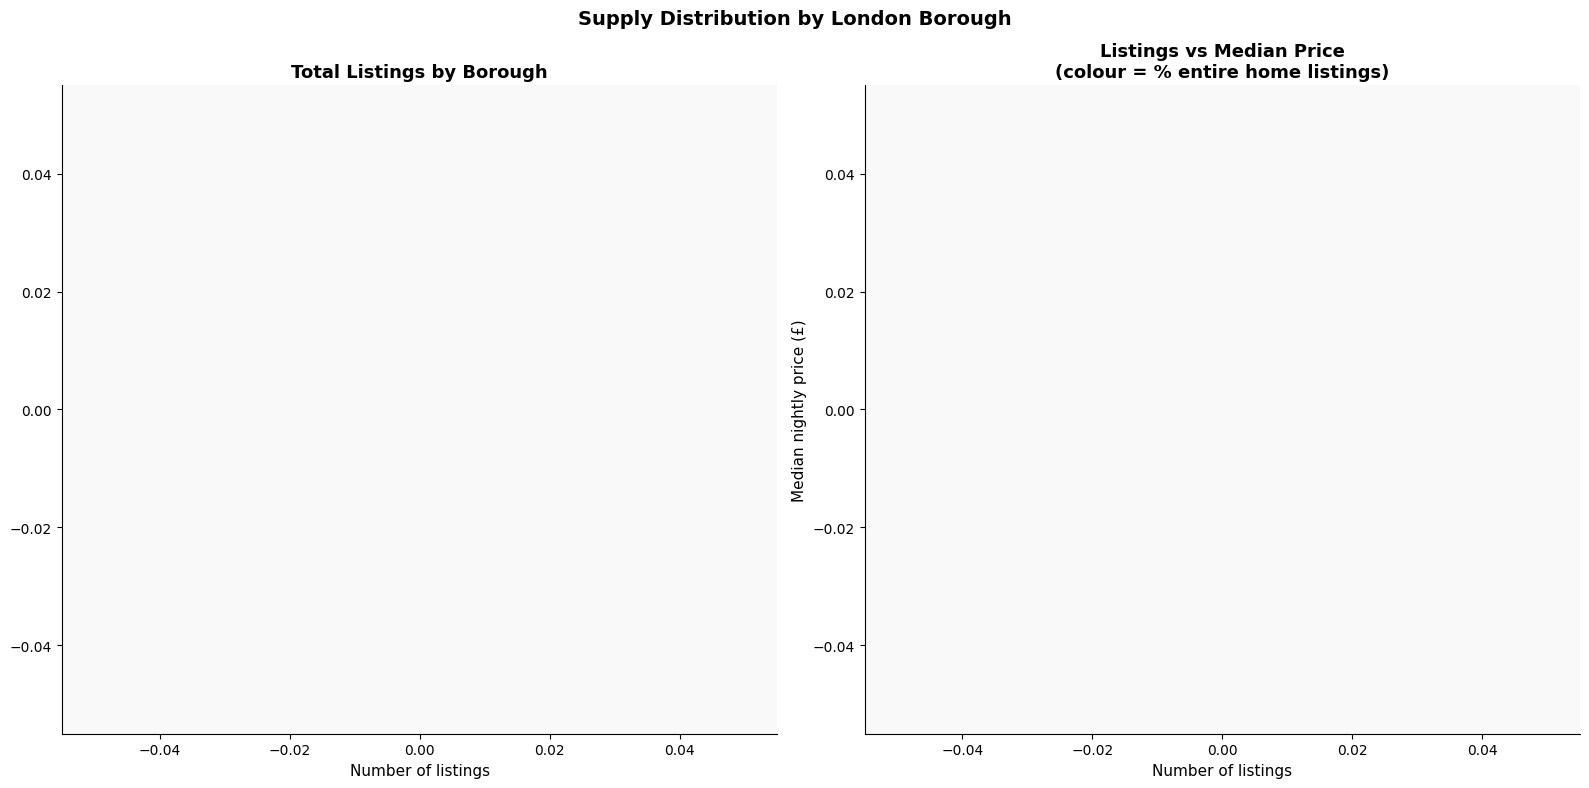

In [7]:
borough_supply = df.groupby(borough_col).agg(
    listings=('id', 'count'),
    hosts=('host_id', 'nunique'),
    median_price=('price', 'median'),
    avg_availability=('availability_365', 'mean'),
    entire_home_pct=('room_type', lambda x: (x == 'Entire home/apt').mean() * 100),
).round(2).sort_values('listings', ascending=False).reset_index()

print("Supply by Borough (Top 15):")
print(borough_supply.head(15).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle('Supply Distribution by London Borough', fontsize=14, fontweight='bold')

top15 = borough_supply.head(15).sort_values('listings', ascending=True)
axes[0].barh(top15[borough_col], top15['listings'],
             color=BLUE, alpha=0.85)
axes[0].set_title('Total Listings by Borough', fontweight='bold')
axes[0].set_xlabel('Number of listings')

axes[1].scatter(borough_supply['listings'], borough_supply['median_price'],
                c=borough_supply['entire_home_pct'], cmap='Blues',
                s=100, alpha=0.8, edgecolors='white', lw=1)
for _, row in borough_supply.head(8).iterrows():
    axes[1].annotate(row[borough_col], (row['listings'], row['median_price']),
                     fontsize=7, xytext=(3, 3), textcoords='offset points')
axes[1].set_title('Listings vs Median Price\n(colour = % entire home listings)',
                  fontweight='bold')
axes[1].set_xlabel('Number of listings')
axes[1].set_ylabel('Median nightly price (£)')

plt.tight_layout()
plt.savefig(FIGURES / '02_supply_by_borough.png', dpi=150, bbox_inches='tight')
plt.show()

borough_supply.to_csv(PROCESSED / 'borough_supply.csv', index=False)


Room type and property type breakdown

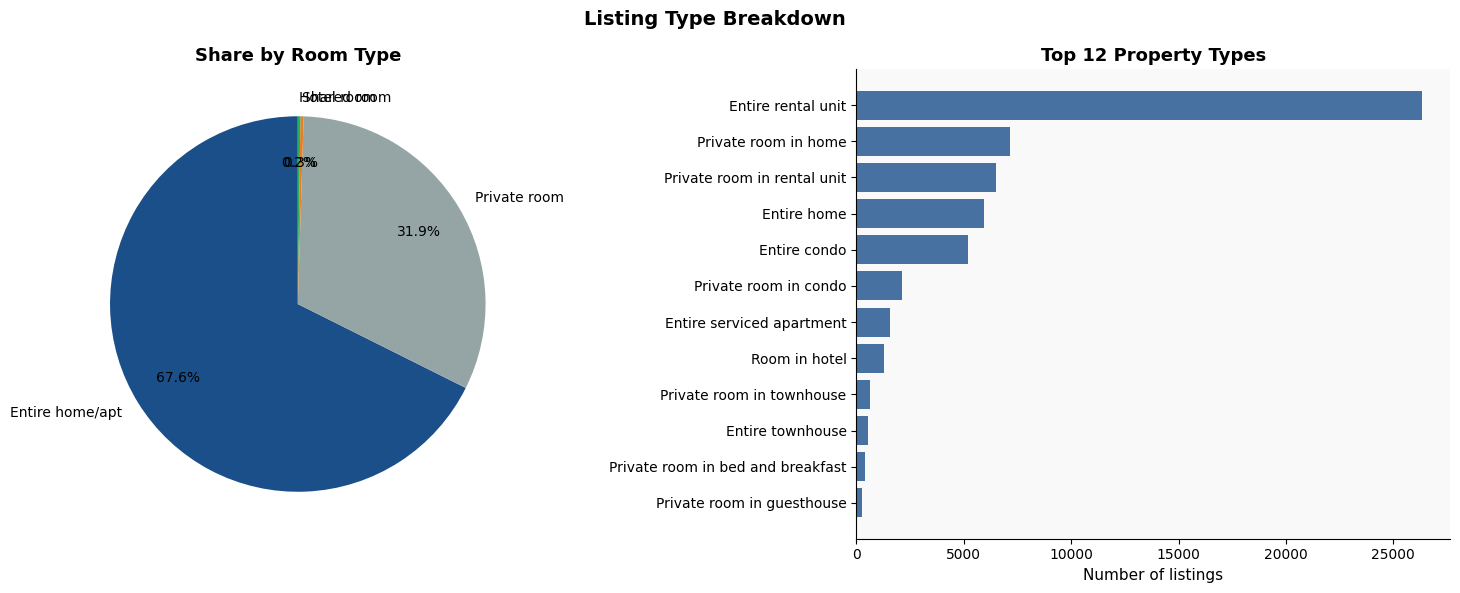

Room type distribution:
  Entire home/apt                  40,447  (67.6%)
  Private room                     19,064  (31.9%)
  Shared room                         165  (0.3%)
  Hotel room                          134  (0.2%)


In [8]:
room_counts = df['room_type'].value_counts()
prop_counts = df['property_type'].value_counts().head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Listing Type Breakdown', fontsize=14, fontweight='bold')

colors_pie = [BLUE, GREY, ORANGE, GREEN]
axes[0].pie(room_counts.values, labels=room_counts.index,
            autopct='%1.1f%%', colors=colors_pie[:len(room_counts)],
            startangle=90, pctdistance=0.75)
axes[0].set_title('Share by Room Type', fontweight='bold')

axes[1].barh(prop_counts.index[::-1], prop_counts.values[::-1],
             color=BLUE, alpha=0.80)
axes[1].set_title('Top 12 Property Types', fontweight='bold')
axes[1].set_xlabel('Number of listings')

plt.tight_layout()
plt.savefig(FIGURES / '03_listing_types.png', dpi=150, bbox_inches='tight')
plt.show()

print("Room type distribution:")
for rt, n in room_counts.items():
    print(f"  {rt:<30}  {n:>7,}  ({n/len(df)*100:.1f}%)")


Availability analysis: how much supply is actually active?

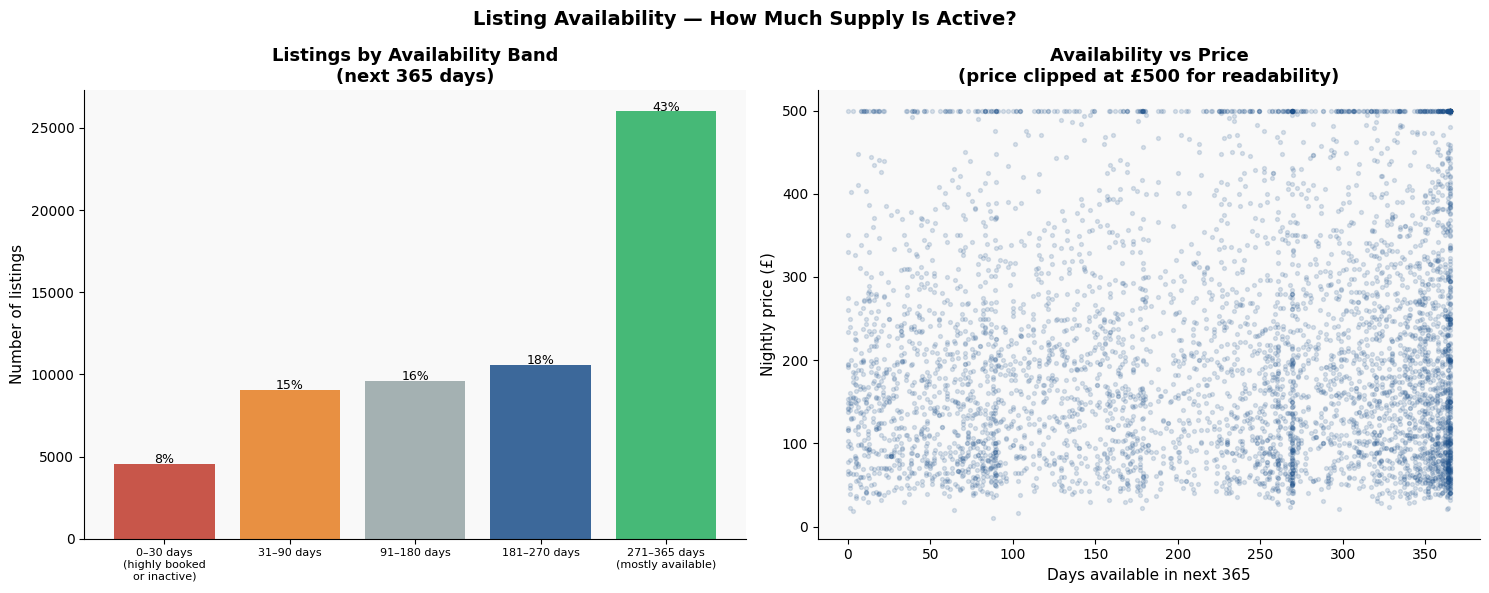


305 listings (0.5%) have zero availability
These are likely inactive or permanently blocked — ghost supply.
True active supply is lower than the raw listing count suggests.


In [9]:
# availability_365 = days available in next 365 days
# 0 = blocked/inactive  |  365 = always available
# Low availability can mean high demand (booked up) OR inactive listing

bins   = [0, 30, 90, 180, 270, 365]
labels = ['0–30 days\n(highly booked\nor inactive)',
          '31–90 days',
          '91–180 days',
          '181–270 days',
          '271–365 days\n(mostly available)']
df['availability_band'] = pd.cut(df['availability_365'], bins=bins, labels=labels, include_lowest=True)

avail_counts = df['availability_band'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Listing Availability — How Much Supply Is Active?', fontsize=14, fontweight='bold')

axes[0].bar(range(len(avail_counts)), avail_counts.values,
            color=[RED, ORANGE, GREY, BLUE, GREEN], alpha=0.85)
axes[0].set_xticks(range(len(avail_counts)))
axes[0].set_xticklabels(avail_counts.index, fontsize=8)
axes[0].set_title('Listings by Availability Band\n(next 365 days)', fontweight='bold')
axes[0].set_ylabel('Number of listings')
for i, v in enumerate(avail_counts.values):
    axes[0].text(i, v + 50, f'{v/len(df)*100:.0f}%', ha='center', fontsize=9)

# Availability vs price
sample = df.sample(min(5000, len(df)), random_state=42)
axes[1].scatter(sample['availability_365'], sample['price'].clip(upper=500),
                alpha=0.15, s=8, color=BLUE)
axes[1].set_title('Availability vs Price\n(price clipped at £500 for readability)',
                  fontweight='bold')
axes[1].set_xlabel('Days available in next 365')
axes[1].set_ylabel('Nightly price (£)')

plt.tight_layout()
plt.savefig(FIGURES / '04_availability_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

inactive = (df['availability_365'] == 0).sum()
print(f"\n{inactive:,} listings ({inactive/len(df)*100:.1f}%) have zero availability")
print("These are likely inactive or permanently blocked — ghost supply.")
print("True active supply is lower than the raw listing count suggests.")


 Superhost analysis

Superhost vs Standard Host comparison:
               listings  median_price  avg_reviews  avg_rating  avg_availability
Standard host     44872        169.00        21.83        4.59            226.22
Superhost         14938        194.58        59.45        4.85            209.38


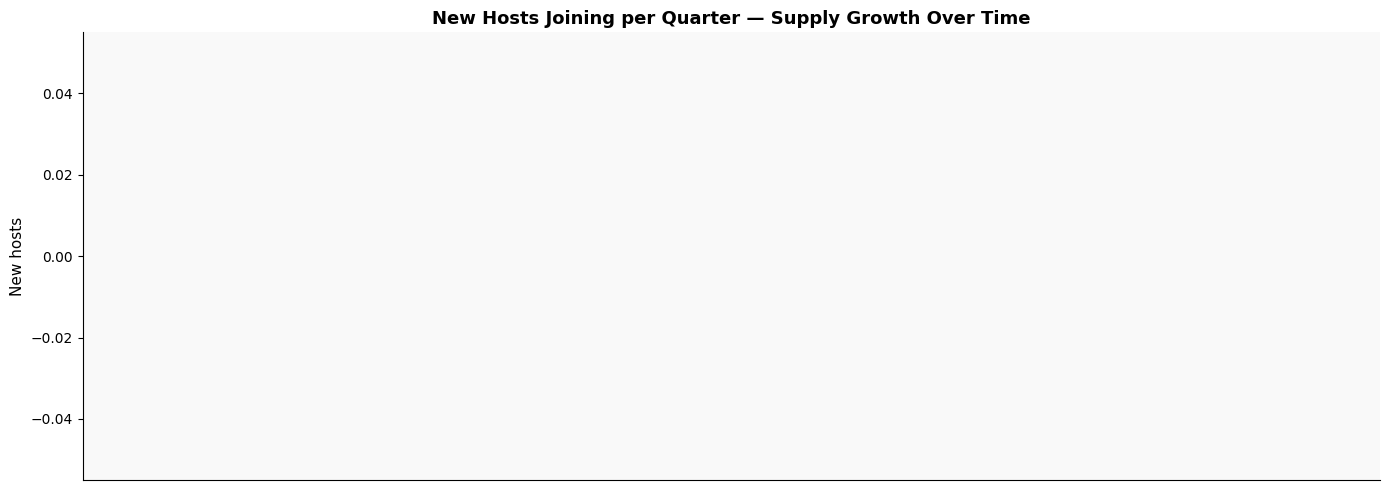

In [10]:
if 'host_is_superhost' in df.columns:
    df['is_superhost'] = df['host_is_superhost'] == 't'

    sh_compare = df.groupby('is_superhost').agg(
        listings=('id', 'count'),
        median_price=('price', 'median'),
        avg_reviews=('number_of_reviews', 'mean'),
        avg_rating=('review_scores_rating', 'mean') if 'review_scores_rating' in df.columns else ('number_of_reviews', 'mean'),
        avg_availability=('availability_365', 'mean'),
    ).round(2)
    sh_compare.index = ['Standard host', 'Superhost']
    print("Superhost vs Standard Host comparison:")
    print(sh_compare.to_string())

    # New hosts over time
    if 'host_since' in df.columns:
        host_cohorts = (df.drop_duplicates('host_id')
                        .dropna(subset=['host_since'])
                        .groupby(df.drop_duplicates('host_id')['host_since'].dt.to_period('Q'))
                        .size().reset_index())
        host_cohorts.columns = ['quarter', 'new_hosts']
        host_cohorts['quarter'] = host_cohorts['quarter'].astype(str)

        fig, ax = plt.subplots(figsize=(14, 5))
        ax.bar(range(len(host_cohorts)), host_cohorts['new_hosts'],
               color=BLUE, alpha=0.8)
        ax.set_xticks(range(0, len(host_cohorts), 4))
        ax.set_xticklabels(host_cohorts['quarter'][::4], rotation=45, ha='right', fontsize=8)
        ax.set_title('New Hosts Joining per Quarter — Supply Growth Over Time', fontweight='bold')
        ax.set_ylabel('New hosts')
        plt.tight_layout()
        plt.savefig(FIGURES / '05_host_growth.png', dpi=150, bbox_inches='tight')
        plt.show()


Save processed listings and summary

In [11]:
# Save lean processed file for dashboard
save_cols = [c for c in [
    'id', 'host_id', 'host_is_superhost', 'host_listings_count',
    borough_col, 'neighbourhood_cleansed',
    'latitude', 'longitude', 'room_type', 'property_type',
    'accommodates', 'bedrooms', 'beds',
    'price', 'minimum_nights',
    'number_of_reviews', 'number_of_reviews_ltm',
    'reviews_per_month', 'last_review',
    'availability_30', 'availability_60',
    'availability_90', 'availability_365',
    'review_scores_rating', 'calculated_host_listings_count',
    'instant_bookable', 'availability_band',
] if c in df.columns]

df[save_cols].to_csv(PROCESSED / 'listings_clean.csv', index=False)
host_listings.to_csv(PROCESSED / 'host_listings.csv', index=False)
borough_supply.to_csv(PROCESSED / 'borough_supply.csv', index=False)

print(f"Saved listings_clean.csv       : {len(df):,} rows")
print(f"Saved host_listings.csv        : {len(host_listings):,} hosts")
print(f"Saved borough_supply.csv       : {len(borough_supply):,} boroughs")
print()
print("Download these before closing Colab.")


Saved listings_clean.csv       : 59,810 rows
Saved host_listings.csv        : 28,959 hosts
Saved borough_supply.csv       : 0 boroughs

Download these before closing Colab.
